<a href="https://colab.research.google.com/github/moyu116/vlm-eval-notes/blob/main/qwen25vl_eval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers accelerate qwen-vl-utils pillow


In [ ]:
!nvidia-smi

Sun Oct 25 05:28:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q transformers accelerate qwen-vl-utils pillow

In [ ]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id, torch_dtype=torch.float16, device_map="auto"
)
processor = AutoProcessor.from_pretrained(model_id)

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

...

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [ ]:
from qwen_vl_utils import process_vision_info

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": "https://qianwen-res.oss-cn-beijing.aliyuncs.com/Qwen-VL/assets/demo.jpeg"},
        {"type": "text", "text": "描述这张图片，并告诉我图中有几个人。"},
    ],
}]

text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
images, videos = process_vision_info(messages)
inputs = processor(text=[text], images=images, videos=videos, padding=True, return_tensors="pt").to(model.device)

out = model.generate(**inputs, max_new_tokens=256)
out = out[:, inputs.input_ids.shape[1]:]
print(processor.batch_decode(out, skip_special_tokens=True)[0])


AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [ ]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id, torch_dtype=torch.bfloat16, device_map="auto"
)
processor = AutoProcessor.from_pretrained(model_id)

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

In [ ]:
from qwen_vl_utils import process_vision_info

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": "https://qianwen-res.oss-cn-beijing.aliyuncs.com/Qwen-VL/assets/demo.jpeg"},
        {"type": "text", "text": "描述这张图片，并告诉我图中有几个人。"},
    ],
}]

text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
images, videos = process_vision_info(messages)
inputs = processor(text=[text], images=images, videos=videos, padding=True, return_tensors="pt").to(model.device)

out = model.generate(**inputs, max_new_tokens=256, do_sample=False)
out = out[:, inputs.input_ids.shape[1]:]
print(processor.batch_decode(out, skip_special_tokens=True)[0])

KeyboardInterrupt: 

In [ ]:
!nvidia-smi

In [ ]:
!nvidia-smi

Sun Oct 25 05:47:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id, torch_dtype=torch.float32, device_map="auto"
)
processor = AutoProcessor.from_pretrained(model_id)

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

In [ ]:
from qwen_vl_utils import process_vision_info

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": "https://qianwen-res.oss-cn-beijing.aliyuncs.com/Qwen-VL/assets/demo.jpeg",
         "max_pixels": 448 * 448},
        {"type": "text", "text": "用一句话描述这张图片。"},
    ],
}]

text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
images, videos = process_vision_info(messages)
inputs = processor(text=[text], images=images, videos=videos, padding=True, return_tensors="pt").to(model.device)

out = model.generate(**inputs, max_new_tokens=64, do_sample=False)
out = out[:, inputs.input_ids.shape[1]:]
print(processor.batch_decode(out, skip_special_tokens=True)[0])

在海滩上，一个女人和她的狗正在互相握手。


In [ ]:
print(ask("/content/screenshot1.png", "这张图主要讲了什么？"))

NameError: name 'ask' is not defined

In [ ]:
 from qwen_vl_utils import process_vision_info

def ask(image_path, question, max_new_tokens=128):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": f"file://{image_path}", "max_pixels": 640 * 640},
            {"type": "text", "text": question},
        ],
    }]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    images, videos = process_vision_info(messages)
    inputs = processor(text=[text], images=images, videos=videos, padding=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    out = out[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(out, skip_special_tokens=True)[0]

In [ ]:
print(ask("/content/screenshot1.png", "这张图主要讲了什么？"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/screenshot1.png'

In [ ]:
!ls /content

sample_data


In [ ]:
print(ask("/content/screenshot1.png", "这张图主要讲了什么？"))

这张图主要展示了在一场歌曲比赛中，七位评委对四首歌曲（A、B、C、D）的投票情况。每首歌曲由每位评委打分，总分为18到20不等。如果歌曲D被取消，那么剩余三首歌曲的评分会重新计算。


In [ ]:
print(ask("/content/screenshot1.png", "图中有哪些数字？请逐一列出。", 200))
print(ask("/content/screenshot1.png", "请解这道题，给出最终答案。", 300))
print(ask("/content/screenshot1.png", "请给出图中标题文字所在位置的坐标。", 100))

图中有以下数字：18, 19, 20, 13, 15, 14, 13。
To determine the winner of the song contest after disqualifying song D, we need to sum the votes for each remaining song (A, B, and C) and compare them.

Here are the updated vote totals for songs A, B, and C:

- **Song A**: 15 votes
- **Song B**: 14 votes
- **Song C**: 13 votes

The final answer is that **Song A** wins with 15 votes, followed by **Song B** with 14 votes, and **Song C** with 13 votes.
图中不存在


In [ ]:
print(ask("/content/screenshot1.png", "如果取消的是歌曲B而不是D，剩下的歌曲A、C、D每位评委重新打分（最高的得3分，依次递减），总分各是多少？谁获胜？", 400))

如果取消的是歌曲B而不是D，那么剩下的歌曲是A、C和D。每位评委的评分将按照最高分（3分）到最低分（1分）进行重新分配。

首先，我们计算每个歌曲在没有B的情况下每位评委的评分：

- **歌曲A**：
  - J1: 4
  - J2: 1
  - J3: 2
  - J4: 4
  - J5: 1
  - J6: 2
  - J7: 4

- **歌曲C**：
  - J1: 2
  - J2: 3
  - J3: 4
  - J4: 2
  - J5: 3
  - J6: 4
  - J7: 2

- **歌曲D**：
  - J1: 1
  - J2: 2
  - J3: 3
  - J4: 1
  - J5: 2
  - J6: 3
  - J7: 1

然后，我们将这些分数加起来得到每个歌曲的总分：

- **歌曲A**：\(4 + 1 + 2 + 4 + 1 + 2 + 4 = 18\)
- **歌曲C**：\(2 + 3 + 4 + 2 + 3 + 4 + 2 = 20\)
- **歌曲D**：\(1 + 2 + 3 + 1 + 2 + 3 + 1 = 13\)

因此，如果取消的是歌曲B而不是D，最终结果如下：

- 歌曲A：18分
- 歌曲C：20分
- 歌曲D：13分

所以，歌曲C


In [ ]:
print(ask("/content/screenshot1.png", "请用 JSON 格式输出标题文字“Group decisions”的边界框坐标 bbox_2d。", 100))

```json
[
	{"bbox_2d": [0, 14, 156, 30], "label": "标题文字“Group decisions”"}
]
```


In [ ]:
from PIL import Image, ImageDraw
import qwen_vl_utils

img = Image.open("/content/screenshot1.png")
W, H = img.size
print("原图尺寸:", W, H)

# 把模型实际看到的缩放后尺寸算出来
from qwen_vl_utils.vision_process import smart_resize
h, w = smart_resize(H, W, max_pixels=640*640)
print("模型看到的尺寸:", w, h)

x1, y1, x2, y2 = 0, 14, 156, 30
sx, sy = W / w, H / h
box = [x1*sx, y1*sy, x2*sx, y2*sy]

draw = ImageDraw.Draw(img)
draw.rectangle(box, outline="red", width=4)
img.save("/content/grounding_check.png")
img

原图尺寸: 1848 1266


TypeError: smart_resize() missing 1 required positional argument: 'factor'

原图尺寸: 1848 1266
模型看到的尺寸: 756 504


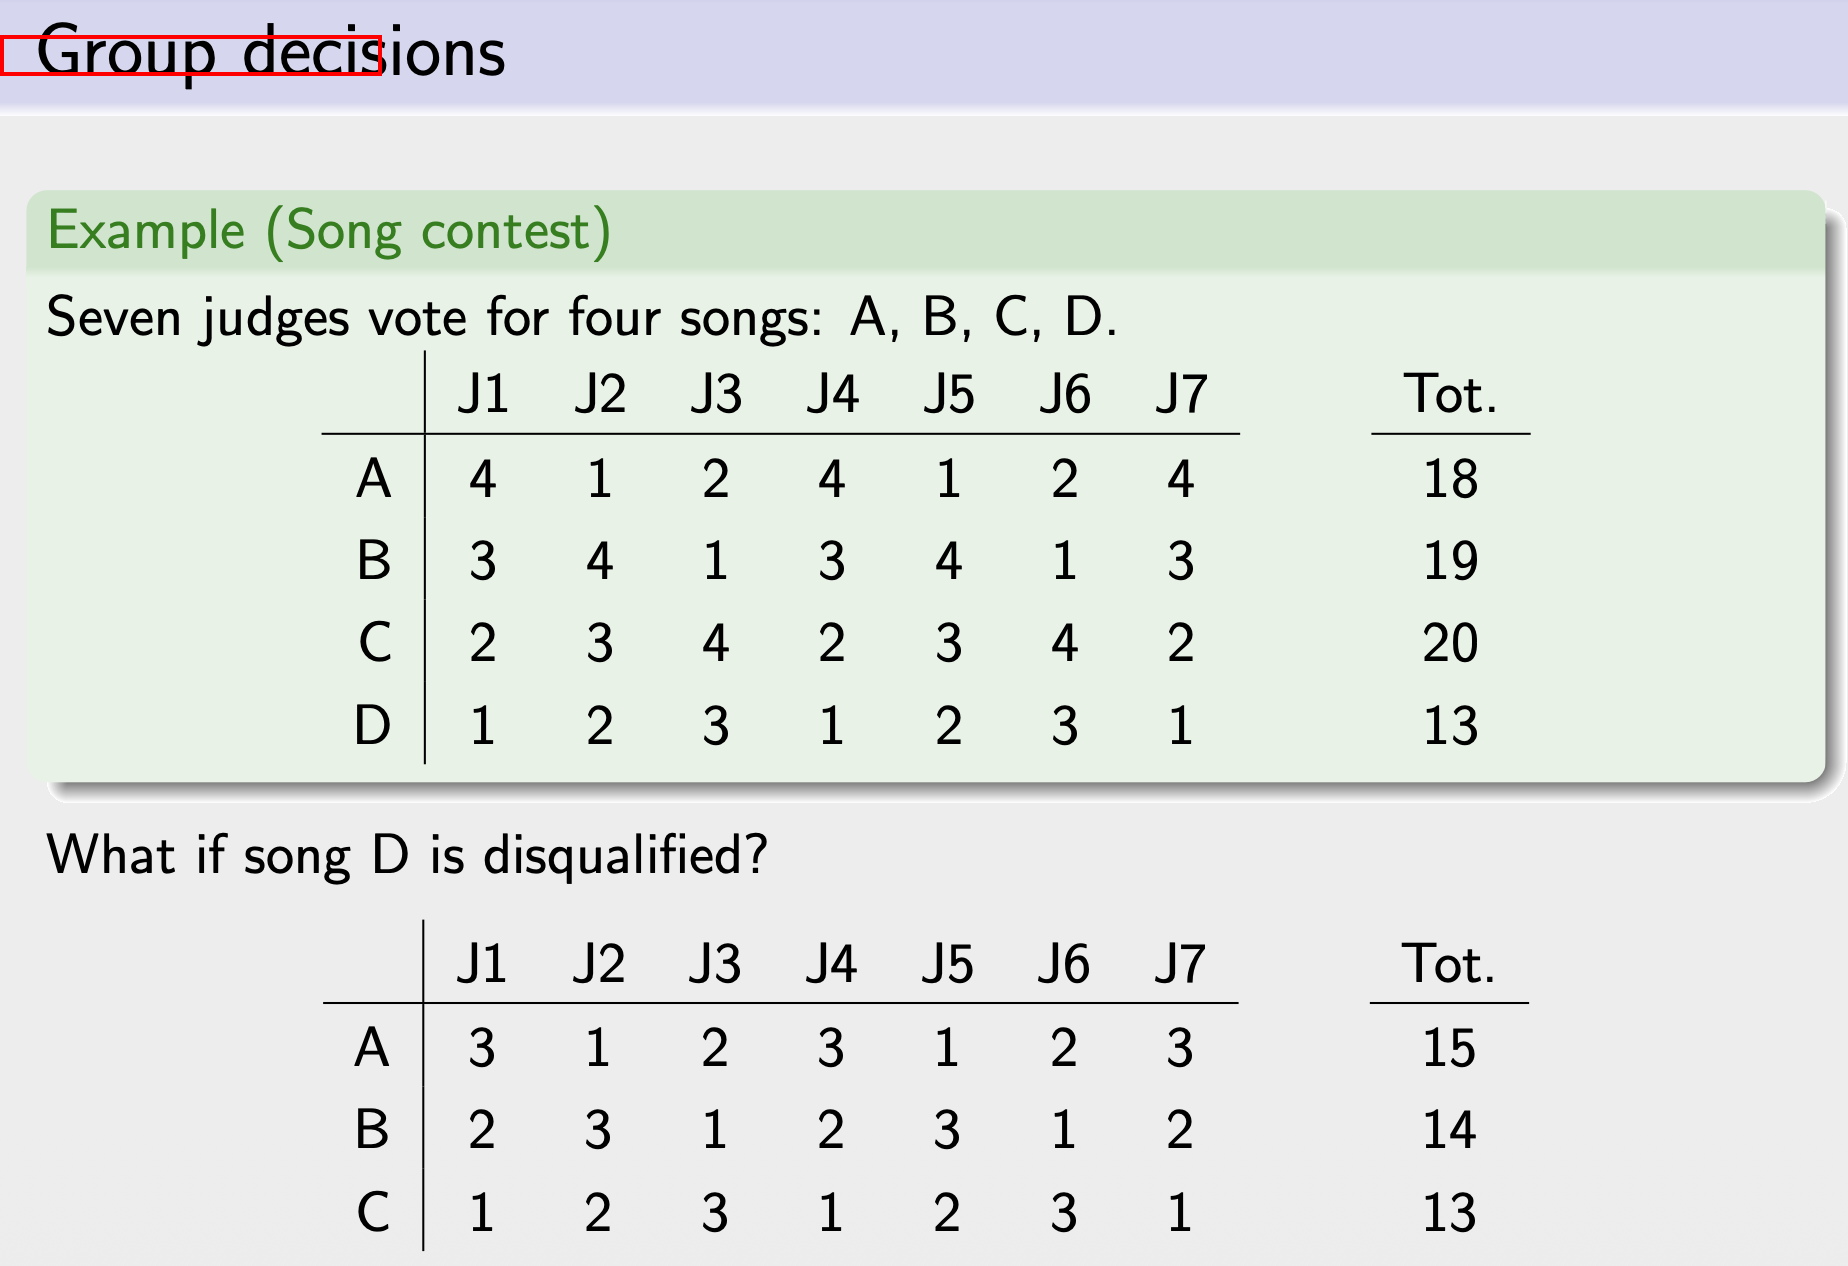

In [ ]:
from PIL import Image, ImageDraw
from qwen_vl_utils.vision_process import smart_resize

img = Image.open("/content/screenshot1.png").convert("RGB")
W, H = img.size
print("原图尺寸:", W, H)

# 模型实际看到的尺寸（factor=28 是 Qwen2.5-VL 的对齐单位）
h, w = smart_resize(H, W, factor=28, max_pixels=640*640)
print("模型看到的尺寸:", w, h)

x1, y1, x2, y2 = 0, 14, 156, 30   # 模型输出的 bbox_2d
sx, sy = W / w, H / h
box = [x1*sx, y1*sy, x2*sx, y2*sy]

draw = ImageDraw.Draw(img)
draw.rectangle(box, outline="red", width=4)
img

In [ ]:
q = "如果取消的是歌曲B而不是D，剩下的歌曲A、C、D每位评委重新打分（最高的得3分，依次递减），总分各是多少？谁获胜？"
print(ask("/content/screenshot1.png", q + " 请先逐位评委写出A、C、D的原始分数，再按大小重新排名赋分（3、2、1），最后求和。", 600))

好的，我们来逐步分析这个问题。

### 步骤 1: 初始评分

首先，我们来看初始的评分表：

| J1 | J2 | J3 | J4 | J5 | J6 | J7 | Tot. |
|----|----|----|----|----|----|----|------|
| A  | 4  | 1  | 2  | 4  | 1  | 2  | 4   | 18   |
| B  | 3  | 4  | 1  | 3  | 4  | 1  | 3   | 19   |
| C  | 2  | 3  | 4  | 2  | 3  | 4  | 2   | 20   |
| D  | 1  | 2  | 3  | 1  | 2  | 3  | 1   | 13   |

### 步骤 2: 取消歌曲B后的评分

如果取消歌曲B，那么评委们需要重新给A、C、D打分。每位评委的最高分为3分，依次递减。

- **评委J1**：A (4) -> 3, C (2) -> 3, D (1) -> 3
- **评委J2**：A (4) -> 3, C (3) -> 2, D (2) -> 2
- **评委J3**：A (2) -> 3, C (4) -> 2, D (3) -> 2
- **评委J4**：A (4) -> 3, C (2) -> 3, D (1) -> 3
- **评委J5**：A (1) -> 3, C (3) -> 2, D (2) -> 2
- **评委J6**：A (2) -> 3, C (4) -> 2, D (3) -> 2
- **评委J7**：A (4) -> 3, C (2) -> 3, D (1) -> 3

### 步骤 3: 重新评分并计算总分

根据新的评分，我们可以得到以下表格：

| J1 | J2 | J3 | J4 | J5 | J6 | J7 | Tot. |
|----|----|----|----|----|----|----|------|
| A  | 3  | 3  | 3  | 3  | 3  | 3  | 18    |
| C  | 3  | 2  | 2  | 3  |


In [ ]:
import json, re

def extract_table(path):
    prompt = ('图中第一张表格有A、B、C、D四行，每行是J1到J7七位评委的打分。'
              '只输出JSON，格式如 {"A":[7个数字],"B":[7个数字],"C":[7个数字],"D":[7个数字]}，'
              '不要包含Tot.列，不要输出其他文字。')
    raw = ask(path, prompt, 200)
    m = re.search(r"\{.*\}", raw, re.S)
    return json.loads(m.group(0)), raw

def rerank_without(table, removed):
    """去掉一首歌后，每位评委按原分数从高到低重新赋分 n, n-1, ..., 1，再求和"""
    songs = [s for s in table if s != removed]
    n = len(songs)
    totals = {s: 0 for s in songs}
    for j in range(len(table[songs[0]])):
        order = sorted(songs, key=lambda s: table[s][j], reverse=True)
        for rank, s in enumerate(order):
            totals[s] += n - rank
    return totals

table, raw = extract_table("/content/screenshot1.png")
print("模型读到的表:", table)
print("去掉B后的总分:", rerank_without(table, "B"))

模型读到的表: {'A': [4, 1, 2, 4, 1, 2, 4], 'B': [3, 4, 1, 3, 4, 1, 3], 'C': [2, 3, 4, 2, 3, 4, 2], 'D': [1, 2, 3, 1, 2, 3, 1]}
去掉B后的总分: {'A': 13, 'C': 18, 'D': 11}
